### Anna Horton - Automated Atlas Homework
ONYEN: arhorton <br>
PID: 730664552

In [62]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages 

<Axes: >

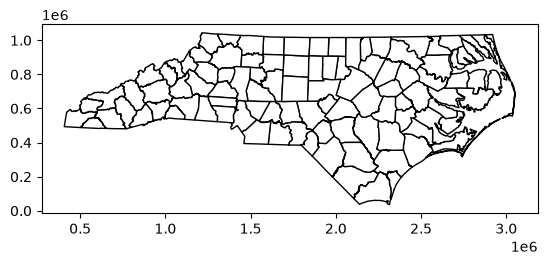

In [63]:
# getting the US census data
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 

## Code for county level data for North Carolina (STATEFP = 37)
counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

## plotting it at the end to make sure there is that characteristic curve at the top that indicates that we are in the correct projection

<Axes: >

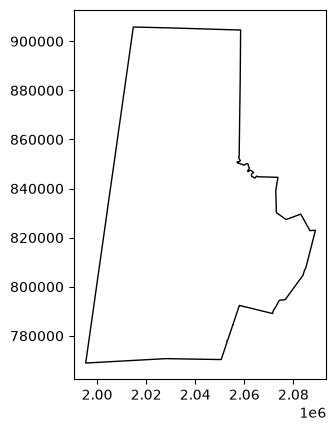

In [64]:
# Map only Durham 
durham = nc_counties[nc_counties["NAME"] == "Durham"]

durham.plot(edgecolor="black", facecolor="white")

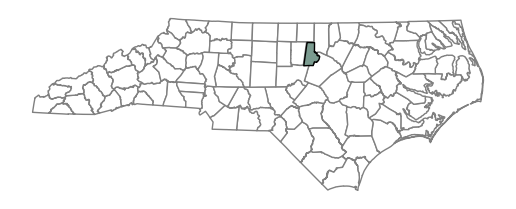

In [65]:
#Let's make a locator map
ax = nc_counties.plot(edgecolor="gray", facecolor="white")

durham.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")

ax.set_axis_off()

In [66]:
## importing my vector layer for my automated atlas
nursing_homes = gpd.read_file("Nursing_Homes.geojson")

## getting a good look at my data
nursing_homes.head()
nursing_homes.columns

## the columns that I likely need to keep are: id, name, county, fips, beds, geometry
nursing_homes = nursing_homes[["id", "name", "county", "fips", "beds", "exc_beds", "geometry"]]
nursing_homes = nursing_homes.to_crs(epsg = 6543)

In [67]:
## Claude helped me with this section, also keeping all of the counties together 
nursing_homes = nursing_homes.to_crs(nc_counties.crs)

joined = gpd.sjoin(
    nursing_homes,
    nc_counties[["NAME", "geometry"]],
    how="left",
    predicate="within",
)

beds = joined.groupby("NAME").agg(
    nursing_homes=("beds", "size"),
    total_beds=("beds", "sum"),
)

counts = joined.groupby("NAME").size().rename("nursing_homes")

nc_counties = (
    nc_counties.merge(counts, on="NAME", how="left")
    .fillna({"nursing_homes": 0, "total_beds": 0})
    .sort_values("NAME")
    .reset_index(drop=True)
)

print(len(nc_counties))  # should be 100
nc_counties.head()

100


,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry,nursing_homes
0,37,001,01008531,0500000US37001,37001,Alamance,Alamance County,NC,North Carolina,06,1096763237,27913357,"POLYGON ((1839468.72 776874.593, 1839558.964 7...",27.0
1,37,003,01008532,0500000US37003,37003,Alexander,Alexander County,NC,North Carolina,06,673368516,9435656,"POLYGON ((1305343.411 764119.949, 1307325.574 ...",4.0
2,37,005,01008533,0500000US37005,37005,Alleghany,Alleghany County,NC,North Carolina,06,608220278,3687222,"POLYGON ((1308931.907 1036329.442, 1317647.375...",1.0
3,37,007,01008534,0500000US37007,37007,Anson,Anson County,NC,North Carolina,06,1376478141,14603213,"POLYGON ((1607201.434 423476.314, 1607481.922 ...",3.0
4,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,"POLYGON ((1193571.583 980437.246, 1194562.461 ...",4.0


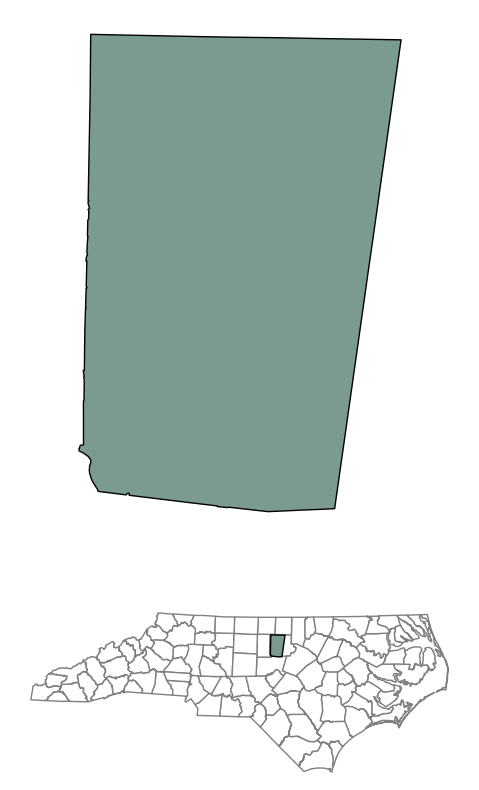

In [68]:
## this function pulls out the map of only the county
def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()

## this code prints out the plot of the entire state of NC and highlights a specific county, whatever is passed as the parameter to the function originally
def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()

## putting them together - this will be a page of the atlas, at its most basic
fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 10),
    gridspec_kw={"height_ratios": [3, 1]}
)

county_map("Orange", axes[0])
locator_map("Orange", axes[1])

plt.show()

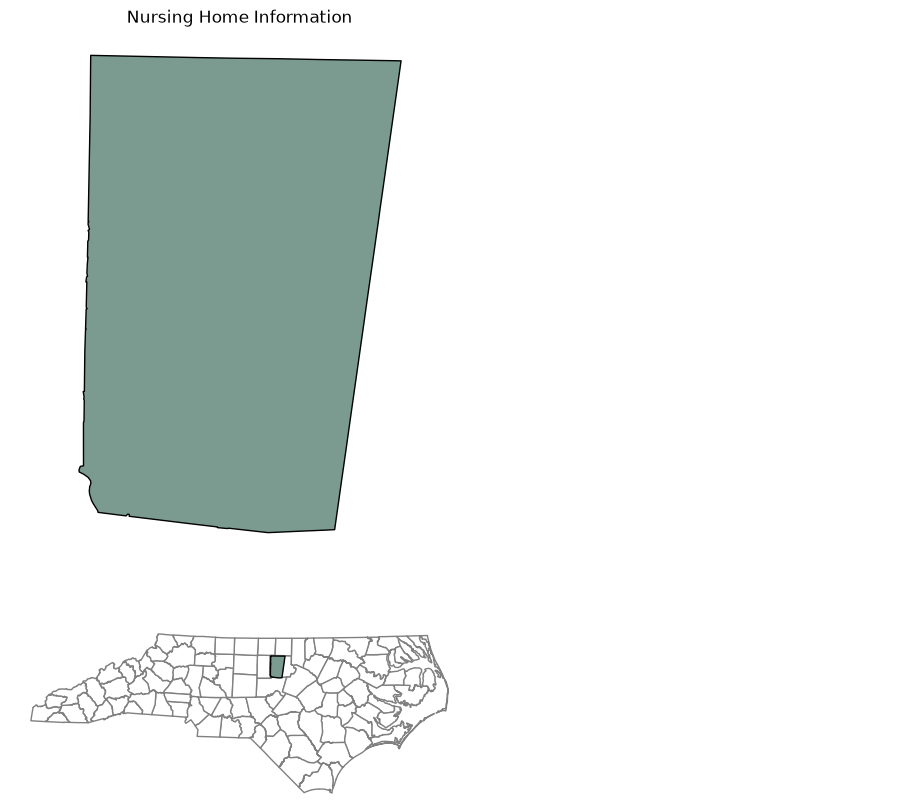

In [69]:
## Moving the figures around so that I can add additional information on the sides of the page
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Orange", axes[0, 0])
locator_map("Orange", axes[1, 0])
axes[0, 0].set_title("Nursing Home Information")

for ax in axes.flat:
    ax.set_axis_off()

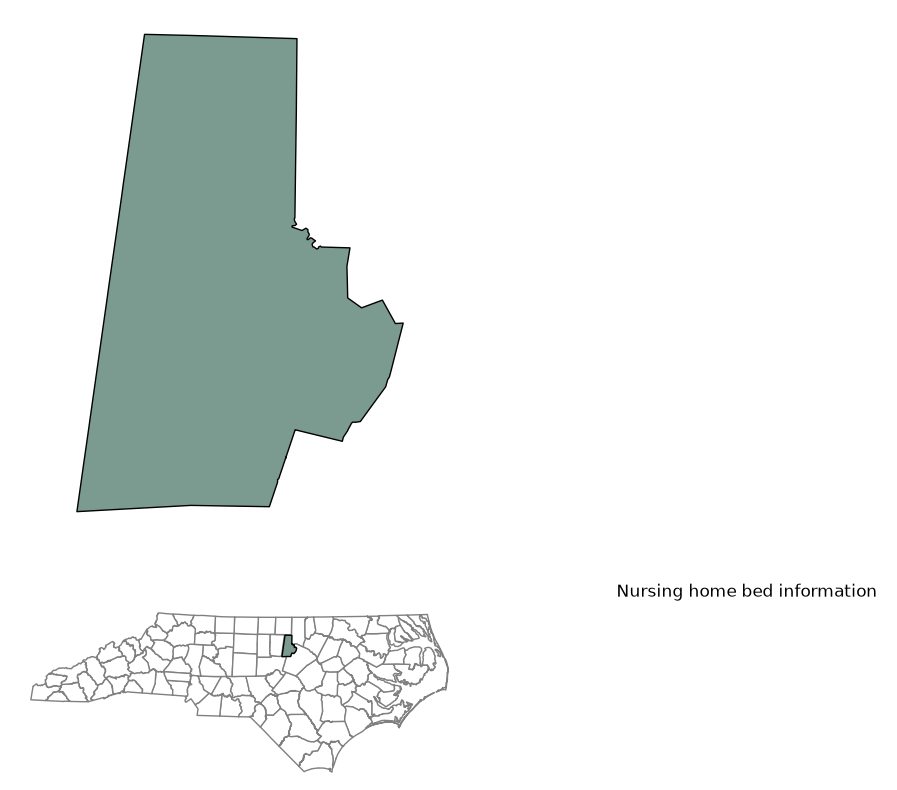

In [70]:
#Let's make the pages a bit more interesting 
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])

axes[1, 1].set_title("Nursing home bed information")

for ax in axes.flat:
    ax.set_axis_off()

Text(0.5, 0.98, 'Durham')

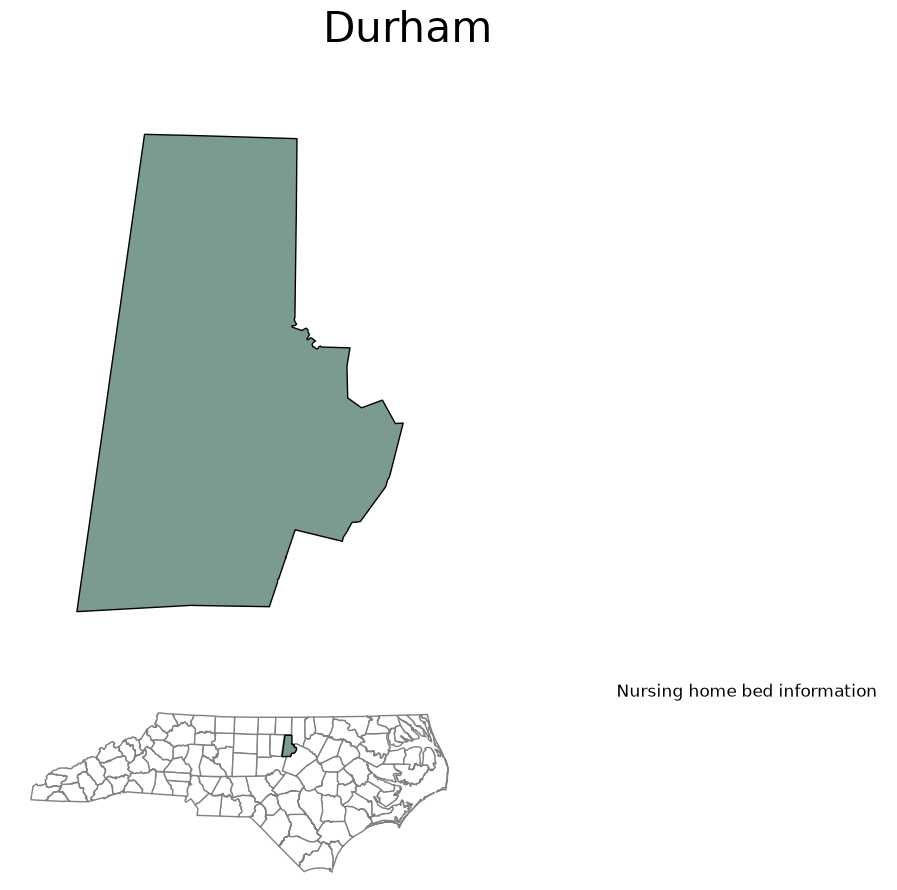

In [71]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])
# axes[0, 1].set_title("Land and water pie chart")
axes[1, 1].set_title("Nursing home bed information")

for ax in axes.flat:
    ax.set_axis_off()

fig.suptitle("Durham", fontsize=30)

Text(0.5, 0.98, 'Durham')

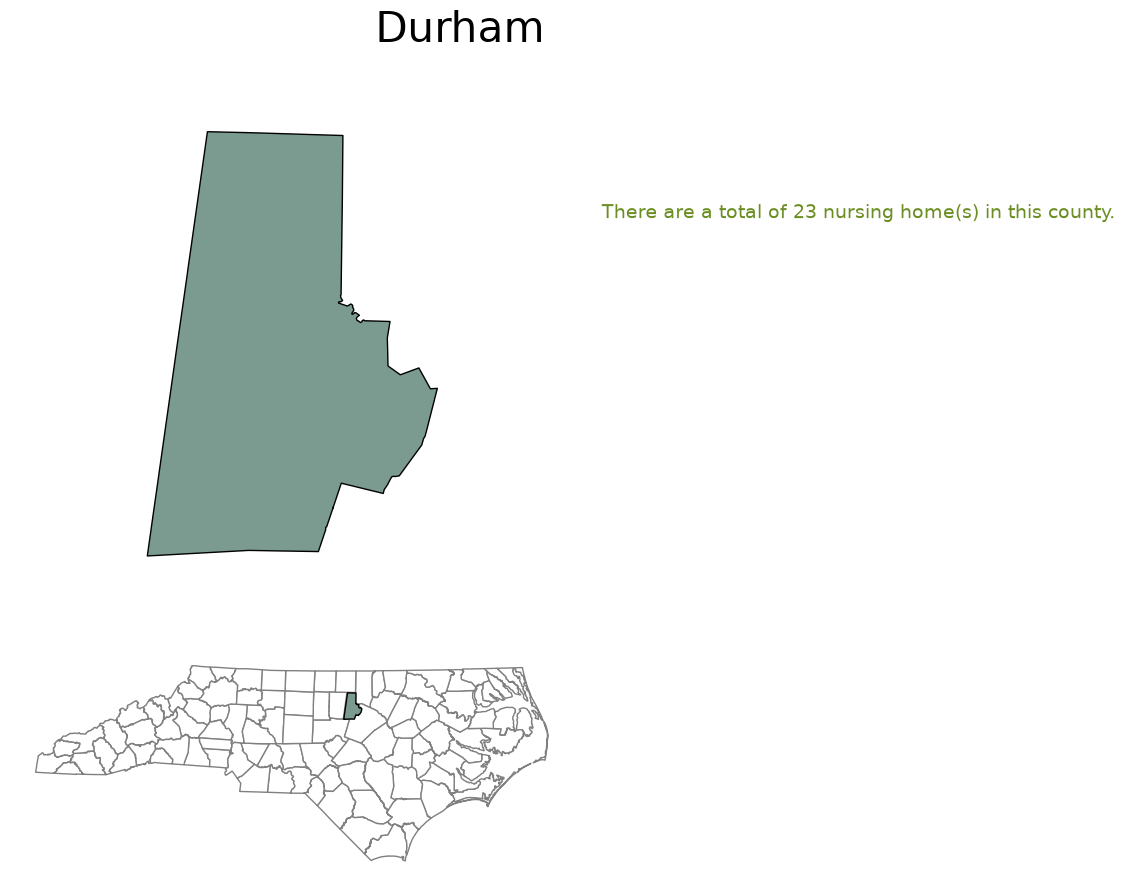

In [72]:
## this is the code that will allow me to print out a little bit more about the county onto the atlas pages
def county_info(county, ax):
    selected = nc_counties.loc[nc_counties["NAME"] == county].iloc[0]
    total_homes = int(selected["nursing_homes"])

    ax.text(
        -.2, 0.8,
        f"There are a total of {total_homes} nursing home(s) in this county.",
        transform=ax.transAxes,
        fontsize=14,
        color="olivedrab",
        va="top"
    )


#Let's make out pages a bit more interesting 
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [2, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])
county_info("Durham",  axes[0,1])

for ax in axes.flat:
    ax.set_axis_off()

fig.suptitle("Durham", fontsize=30)

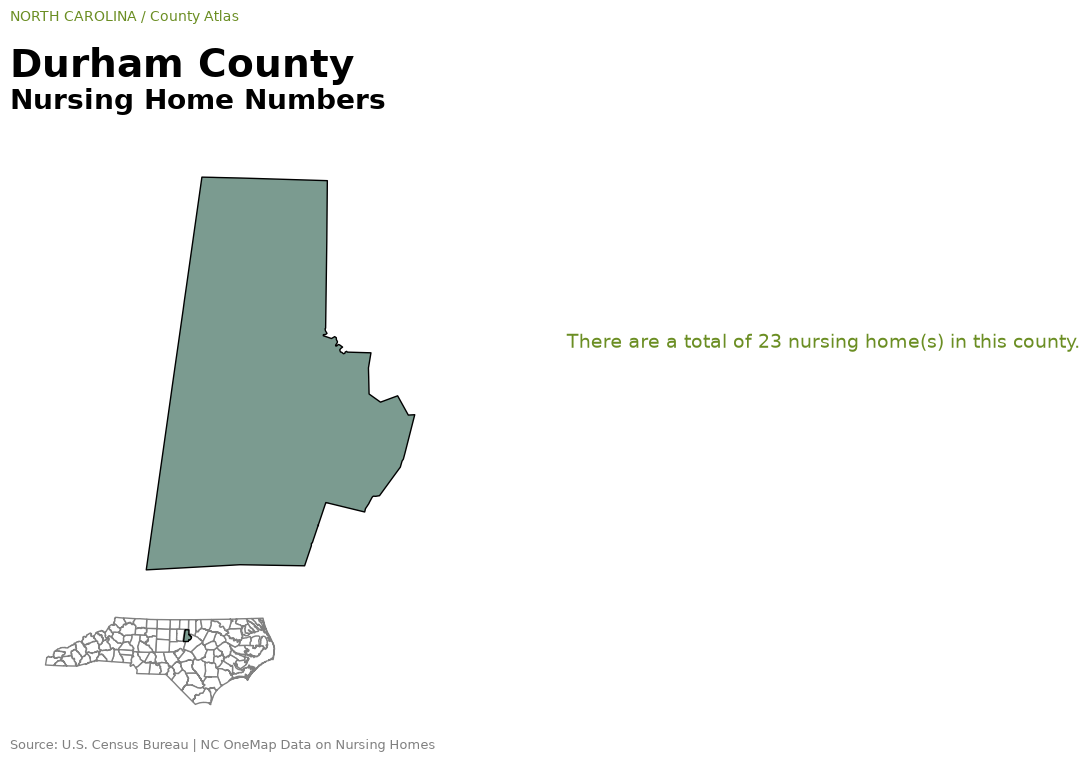

In [73]:
#Let's make it nicer and prettier for the PDF

county = "Durham"

fig = plt.figure(figsize=(12, 8))
ax_county = fig.add_axes([0.00, 0.23, 0.55, 0.54])
ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
ax_info = fig.add_axes([0.55, 0.35, 0.18, 0.25])

county_map(county, ax_county)
locator_map(county, ax_locator)
county_info(county, ax_info)

for ax in (ax_county, ax_locator, ax_info):
    ax.set_axis_off()

# Page heading
fig.text(
    0.05, 0.94,
    "NORTH CAROLINA / County Atlas",
    fontsize=10,
    color="olivedrab"
)

fig.text(
    0.05, 0.87,
    f"{county} County",
    fontsize=28,
    fontweight="bold"
)

fig.text(
    .05, .83,
    f"Nursing Home Numbers",
    fontsize = 20,
    fontweight = "bold"
)

# Footer
fig.text(
    0.05, 0.03,
    "Source: U.S. Census Bureau | NC OneMap Data on Nursing Homes",
    fontsize=9,
    color="gray"
)


plt.show()

In [74]:
#Let's make it a function

def county_figure(county, pdf):

    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    # Coded with Ai help
    ax_county = fig.add_axes([0.00, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
    ax_info = fig.add_axes([0.55, 0.35, 0.18, 0.25])


    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)

    for ax in (ax_county, ax_locator, ax_info):
        ax.set_axis_off()

    # Page heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / County Atlas",
        fontsize=10,
        color="olivedrab"
    )

    fig.text(
        0.05, 0.87,
        f"{county} County",
        fontsize=28,
        fontweight="bold"
    )

    fig.text(
    .05, .83,
    f"Nursing Home Numbers",
    fontsize = 20,
    fontweight = "bold"
)

    # Footer
    fig.text(
        0.05, 0.03,
        "Source: U.S. Census Bureau | NC OneMap Data on Nursing Homes",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig, dpi=50)
    plt.close(fig)

In [75]:
## code came from Claude, trying to diagnose the PDF loading issue
import time

def timed(label, fn, *args):
    t = time.time()
    fn(*args)
    print(f"{label}: {time.time() - t:.2f}s")

fig = plt.figure(figsize=(12, 8))
ax1 = fig.add_axes([0.05, 0.23, 0.55, 0.54])
ax2 = fig.add_axes([0.05, 0.08, 0.25, 0.12])
ax3 = fig.add_axes([0.65, 0.12, 0.30, 0.32])

timed("county_map", county_map, "Orange", ax1)
timed("locator_map", locator_map, "Orange", ax2)
timed("county_info", county_info, "Orange", ax3)
plt.close(fig)

county_map: 0.04s
locator_map: 0.06s
county_info: 0.00s


In [76]:
## code came from Claude, trying to diagnose the PDF loading issue
import time
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("test.pdf") as pdf:
    t = time.time()
    county_figure("Orange", pdf)
    print(f"full page: {time.time() - t:.2f}s")

full page: 0.18s


In [77]:
print(len(nc_counties))

100


In [79]:
nc_counties = nc_counties.sort_values("NAME").reset_index(drop=True)

with PdfPages("NC_Counties_NursingHomes.pdf") as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

## AI statement
1) I used Claude AI. 
2) I had to use Claude because my PDF export was taking over 10 minutes and exporting thousands of pages instead of 100 (and I'm not sure why). I then found out my spatial join had converted my file of 100 rows to over 1000, which was the issue. I asked it to help diagnose that issue and then help me fix my spatial join. I also had to ask it to help me with my loop - the issue was that it was only printing the number of nursing homes in the first county and not scaling for the remainder. 
3) I had coded the spatial join the PDF Pages method. However, both were incorrect, as I quickly found out, and Claude helped me to diagnose the issue (as seen from the diagnostic code blocks above) and fix the issue itself. It helped me to bring my counties layer back to 100 counties (after going from 1028 to 99 and back to 100), which solved my PDF loading issue. It helped me to use the code that the professor provided and switch it slightly to account for my purposes. 
4) I changed the format of the spatial join to aggregate by the count of nursing homes in each of the counties with a merge parameter. I also wrote in code to ensure that the counties that didn't have any nursing homes would also be counted within the pages (as it had been dropping them earlier). These fixes helped the PDF print in just 15 seconds instead of the over 11 minutes it was previously taking. I adjusted the function to print out the number of nursing homes for each county and used the .iloc[] that was already in there to scale. 
